# Desigualdade educacional no Brasil: previsão do desempenho em Matemática no ENEM 2023 com Apache Spark ML

**Disciplina:** Processamento de Dados Massivos  
**Professor:** Alexandre Roriz

## Objetivo
Investigar a associação entre características socioeconômicas dos participantes e o desempenho na prova de Matemática do ENEM 2023, utilizando um modelo de regressão implementado com Apache Spark ML.

## Fonte dos dados
Instituto Nacional de Estudos e Pesquisas Educacionais Anísio Teixeira (INEP). Microdados do ENEM 2023.

https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/microdados/enem

## Justificativa
O ENEM reúne milhões de registros, com características demográficas, respostas ao questionário socioeconômico e resultados das provas. Em cenários reais que envolvem múltiplas edições, a análise pode demandar processamento distribuído para ampliar a capacidade e a eficiência de tratamento dos dados. Neste projeto, o Spark será executado inicialmente em modo local no Google Colab, como demonstração da tecnologia.

## Questão de pesquisa
Em que medida características socioeconômicas estão associadas às notas de Matemática dos participantes do ENEM 2023?

**Tipo de problema:** regressão. **Unidade de análise:** inscrição do participante na edição 2023. **Variável resposta:** nota de Matemática. **Variáveis preditoras:** escolaridade dos responsáveis, renda familiar, acesso à internet e tipo de escola.


### Justificativa para o uso de processamento de dados massivos

O ENEM é uma avaliação nacional que produz milhões de registros por edição, reunindo informações sobre participantes, características socioeconômicas e desempenho nas provas.

Neste trabalho, foram processados aproximadamente 3,9 milhões de registros da edição de 2023, dos quais cerca de 2,69 milhões foram selecionados para a análise de regressão.

A análise de diferentes edições do exame, considerando um período de vários anos, aumentaria significativamente o volume de dados. Além disso, operações como agrupamentos, tratamento de valores ausentes, transformações de variáveis e treinamento de modelos de Machine Learning podem exigir recursos computacionais elevados.

Nesse cenário, o processamento distribuído permite dividir operações entre diferentes recursos computacionais, ampliando a capacidade de processamento e contribuindo para a escalabilidade das análises.

O Apache Spark foi utilizado por oferecer recursos de processamento paralelo, manipulação de grandes conjuntos de dados e integração com algoritmos de Machine Learning por meio do Spark ML.

Neste projeto, a execução ocorreu em modo local no Google Colab. Portanto, não foi utilizado um cluster com múltiplas máquinas, mas a tecnologia e as operações empregadas são compatíveis com cenários de processamento distribuído.

> **Reprodutibilidade:** o notebook tenta obter o ZIP no servidor oficial do INEP. Se o download falhar, utiliza uma cópia previamente baixada do INEP no Google Drive do autor; essa alternativa exige configurar o caminho e conceder acesso ao arquivo. Não publique os microdados nem o modelo ZIP no GitHub. O procedimento do Drive é um contingenciamento e não garante reprodução por terceiros.

> **Nota metodológica:** os resultados finais foram obtidos no Colab pela autora. O notebook revisado precisa ser executado integralmente em sessão limpa para verificar a reprodução. O conjunto de teste foi consultado durante o desenvolvimento e isso limita sua independência metodológica.

In [1]:
# ETAPA 1 - Configuração do ambiente

!pip -q install pyspark

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql.types import (
    StructType, StructField, StringType, DoubleType
)

import os
import csv
import zipfile
import requests
import shutil
import matplotlib.pyplot as plt
import pandas as pd

spark = (
    SparkSession.builder
    .appName("ENEM_2023_Desigualdade_Educacional")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

print("Spark iniciado com sucesso!")
print("Versão:", spark.version)


Spark iniciado com sucesso!
Versão: 4.0.5


In [2]:
# ============================================================
# ETAPA 2 - OBTENÇÃO DOS MICRODADOS DO ENEM 2023
# Fonte oficial: INEP
# Alternativa: arquivo original armazenado no Google Drive
# ============================================================

from google.colab import drive

# Endereço oficial dos microdados do ENEM 2023
url_inep = (
    "https://download.inep.gov.br/microdados/"
    "microdados_enem_2023.zip"
)

# Pasta local do Google Colab
pasta = "/content/enem_2023"
os.makedirs(pasta, exist_ok=True)

arquivo_zip = os.path.join(
    pasta, "microdados_enem_2023.zip"
)

# Caminho completo do arquivo no Google Drive
arquivo_drive = (
    "/content/drive/MyDrive/Classroom/"
    "Processamento de Dados Massivos CIANM3B-CIA033-20262 - IESB SUL/"
    "Projeto_ENEM_2023/microdados_enem_2023.zip"
)

# Função para verificar a integridade do arquivo ZIP
def zip_valido(caminho):
    try:
        with zipfile.ZipFile(caminho) as z:
            return z.testzip() is None
    except (OSError, zipfile.BadZipFile):
        return False


# ============================================================
# PRIMEIRA OPÇÃO - DOWNLOAD AUTOMÁTICO DO INEP
# ============================================================

if not os.path.isfile(arquivo_zip) or not zip_valido(arquivo_zip):

    print("Tentando baixar diretamente do INEP...")

    try:
        with requests.get(
            url_inep,
            stream=True,
            timeout=(20, 60)
        ) as resposta:

            resposta.raise_for_status()

            with open(arquivo_zip, "wb") as arquivo:
                for bloco in resposta.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if bloco:
                        arquivo.write(bloco)

        if not zip_valido(arquivo_zip):
            raise ValueError("ZIP incompleto ou corrompido.")

        print("Download oficial realizado com sucesso!")

    except (requests.RequestException, OSError, ValueError) as erro:

        print("Download automático indisponível.")
        print("Motivo:", erro)

        if os.path.exists(arquivo_zip):
            os.remove(arquivo_zip)

        # ====================================================
        # SEGUNDA OPÇÃO - ARQUIVO ORIGINAL NO GOOGLE DRIVE
        # ====================================================

        print("\nBuscando arquivo original no Google Drive...")

        drive.mount("/content/drive")

        if not os.path.isfile(arquivo_drive):
            raise FileNotFoundError(
                "Arquivo não encontrado no Google Drive. "
                "Verifique o caminho informado."
            )

        if not zip_valido(arquivo_drive):
            raise ValueError(
                "O arquivo ZIP do Google Drive está corrompido."
            )

        arquivo_zip = arquivo_drive

        print("Arquivo original encontrado no Google Drive!")

else:
    print("Arquivo oficial já disponível no Colab.")


# ============================================================
# RESULTADO DA ETAPA 2
# ============================================================

print("\n========== RESULTADO ==========")
print("Base selecionada:", arquivo_zip)

print(
    "Tamanho do arquivo:",
    round(os.path.getsize(arquivo_zip) / 1024**3, 2),
    "GB"
)

print("Etapa 2 concluída com sucesso!")

Tentando baixar diretamente do INEP...
Download automático indisponível.
Motivo: ('Connection aborted.', ConnectionResetError(104, 'Connection reset by peer'))

Buscando arquivo original no Google Drive...
Mounted at /content/drive
Arquivo original encontrado no Google Drive!

========== RESULTADO ==========
Base selecionada: /content/drive/MyDrive/Classroom/Processamento de Dados Massivos CIANM3B-CIA033-20262 - IESB SUL/Projeto_ENEM_2023/microdados_enem_2023.zip
Tamanho do arquivo: 0.51 GB
Etapa 2 concluída com sucesso!


In [3]:
# ETAPA 3 - Extração dos microdados do ENEM 2023

pasta_extracao = "/content/enem_2023/dados"
os.makedirs(pasta_extracao, exist_ok=True)

with zipfile.ZipFile(arquivo_zip) as z:
    nome_csv = next(
        (nome for nome in z.namelist()
         if os.path.basename(nome).upper() == "MICRODADOS_ENEM_2023.CSV"),
        None
    )

    if nome_csv is None:
        raise FileNotFoundError("CSV do ENEM 2023 não encontrado.")

    caminho_csv = os.path.join(pasta_extracao, "MICRODADOS_ENEM_2023.csv")

    tamanho_esperado = z.getinfo(nome_csv).file_size
    if (not os.path.exists(caminho_csv)
            or os.path.getsize(caminho_csv) != tamanho_esperado):
        with z.open(nome_csv) as origem, open(caminho_csv, "wb") as destino:
            shutil.copyfileobj(origem, destino)

print("CSV disponível:", caminho_csv)
print("Tamanho (GB):", round(os.path.getsize(caminho_csv) / 1024**3, 2))


CSV disponível: /content/enem_2023/dados/MICRODADOS_ENEM_2023.csv
Tamanho (GB): 1.66


In [4]:
# ETAPA 4 - Verificação das variáveis do projeto

variaveis = {
    "Q001": "Escolaridade do pai",
    "Q002": "Escolaridade da mãe",
    "Q006": "Renda familiar",
    "Q025": "Acesso à internet",
    "TP_ESCOLA": "Tipo de escola",
    "NU_NOTA_MT": "Nota de Matemática",
    "NU_NOTA_REDACAO": "Nota da Redação",
    "TP_PRESENCA_MT": "Presença na prova de Matemática"
}

with open(caminho_csv, encoding="latin1", newline="") as arquivo:
    colunas = next(csv.reader(arquivo, delimiter=";"))

print("Total de colunas da base:", len(colunas))

for codigo, descricao in variaveis.items():
    status = "OK" if codigo in colunas else "NÃO ENCONTRADA"
    print(f"{status} - {codigo}: {descricao}")


Total de colunas da base: 76
OK - Q001: Escolaridade do pai
OK - Q002: Escolaridade da mãe
OK - Q006: Renda familiar
OK - Q025: Acesso à internet
OK - TP_ESCOLA: Tipo de escola
OK - NU_NOTA_MT: Nota de Matemática
OK - NU_NOTA_REDACAO: Nota da Redação
OK - TP_PRESENCA_MT: Presença na prova de Matemática


In [5]:
# ETAPA 5 - Inspeção das variáveis antes da leitura com Spark

with open(caminho_csv, encoding="latin1", newline="") as arquivo:
    leitor = csv.DictReader(arquivo, delimiter=";")

    for i, registro in enumerate(leitor):
        print(f"\nParticipante {i + 1}")

        for codigo, descricao in variaveis.items():
            print(f"{codigo} ({descricao}): {registro[codigo]}")

        if i == 4:
            break


Participante 1
Q001 (Escolaridade do pai): A
Q002 (Escolaridade da mãe): F
Q006 (Renda familiar): F
Q025 (Acesso à internet): B
TP_ESCOLA (Tipo de escola): 1
NU_NOTA_MT (Nota de Matemática): 
NU_NOTA_REDACAO (Nota da Redação): 
TP_PRESENCA_MT (Presença na prova de Matemática): 0

Participante 2
Q001 (Escolaridade do pai): F
Q002 (Escolaridade da mãe): E
Q006 (Renda familiar): H
Q025 (Acesso à internet): B
TP_ESCOLA (Tipo de escola): 1
NU_NOTA_MT (Nota de Matemática): 
NU_NOTA_REDACAO (Nota da Redação): 
TP_PRESENCA_MT (Presença na prova de Matemática): 0

Participante 3
Q001 (Escolaridade do pai): H
Q002 (Escolaridade da mãe): E
Q006 (Renda familiar): C
Q025 (Acesso à internet): B
TP_ESCOLA (Tipo de escola): 1
NU_NOTA_MT (Nota de Matemática): 363.2
NU_NOTA_REDACAO (Nota da Redação): 700
TP_PRESENCA_MT (Presença na prova de Matemática): 1

Participante 4
Q001 (Escolaridade do pai): D
Q002 (Escolaridade da mãe): D
Q006 (Renda familiar): C
Q025 (Acesso à internet): B
TP_ESCOLA (Tipo de e

In [6]:
# ETAPA 6 - Leitura dos dados com PySpark

schema_enem = StructType([
    StructField(
        c,
        DoubleType() if c in ["NU_NOTA_MT", "NU_NOTA_REDACAO"]
        else StringType(),
        True
    )
    for c in colunas
])

df_original = (
    spark.read
    .option("header", True)
    .option("sep", ";")
    .option("encoding", "ISO-8859-1")
    .schema(schema_enem)
    .csv(caminho_csv)
)

df_enem = df_original.select(*variaveis.keys())

print("Estrutura das variáveis selecionadas:")
df_enem.printSchema()

Estrutura das variáveis selecionadas:
root
 |-- Q001: string (nullable = true)
 |-- Q002: string (nullable = true)
 |-- Q006: string (nullable = true)
 |-- Q025: string (nullable = true)
 |-- TP_ESCOLA: string (nullable = true)
 |-- NU_NOTA_MT: double (nullable = true)
 |-- NU_NOTA_REDACAO: double (nullable = true)
 |-- TP_PRESENCA_MT: string (nullable = true)



In [7]:
# ETAPA 7 - Contagem e validação dos registros

total = df_enem.count()

df_presentes = df_enem.filter(
    (F.col("TP_PRESENCA_MT") == "1") &
    F.col("NU_NOTA_MT").between(0, 1000)
)

total_validos = df_presentes.count()

print(f"Total de registros: {total:,}")
print(f"Registros válidos para Matemática: {total_validos:,}")
print(f"Registros não selecionados: {total - total_validos:,}")
print(f"Percentual válido: {total_validos / total * 100:.2f}%")

Total de registros: 3,933,955
Registros válidos para Matemática: 2,692,427
Registros não selecionados: 1,241,528
Percentual válido: 68.44%


### Caracterização inicial da base

A base de microdados do ENEM 2023, disponibilizada pelo INEP, contém 3.933.955 registros de participantes.

Para o desenvolvimento do modelo de regressão, foram selecionados os participantes que compareceram à prova de Matemática e apresentaram notas válidas, entre 0 e 1.000 pontos.

Após essa seleção, permaneceram 2.692.427 registros, correspondentes a 68,44% da base original.

O volume de dados atende ao requisito mínimo de 200 mil registros estabelecido para o trabalho e permite realizar análises das relações entre características socioeconômicas e desempenho em Matemática utilizando Apache Spark.

In [8]:
# ETAPA 8 - Verificação de valores ausentes

df_presentes.select([
    F.sum(
        F.when(
            F.col(c).isNull() |
            (F.trim(F.col(c).cast("string")) == ""),
            1
        ).otherwise(0)
    ).alias(c)
    for c in df_presentes.columns
]).show(truncate=False)

+----+----+----+----+---------+----------+---------------+--------------+
|Q001|Q002|Q006|Q025|TP_ESCOLA|NU_NOTA_MT|NU_NOTA_REDACAO|TP_PRESENCA_MT|
+----+----+----+----+---------+----------+---------------+--------------+
|0   |0   |0   |0   |0        |0         |14163          |0             |
+----+----+----+----+---------+----------+---------------+--------------+



In [9]:
# ETAPA 9 - Estatísticas descritivas das notas

df_presentes.select(
    "NU_NOTA_MT",
    "NU_NOTA_REDACAO"
).describe().show()

+-------+------------------+------------------+
|summary|        NU_NOTA_MT|   NU_NOTA_REDACAO|
+-------+------------------+------------------+
|  count|           2692427|           2678264|
|   mean| 533.8357003179672| 626.6020153353068|
| stddev|131.64777439097904|209.03205739962885|
|    min|               0.0|               0.0|
|    max|             958.6|            1000.0|
+-------+------------------+------------------+



In [10]:
# ETAPA 10 - Identificação e validação de duplicatas

# 1. Verificação inicial das combinações repetidas
total_distintos = df_presentes.distinct().count()
combinacoes_repetidas = total_validos - total_distintos

print("VERIFICAÇÃO INICIAL")
print(f"Total de registros: {total_validos:,}")
print(f"Combinações distintas: {total_distintos:,}")
print(f"Combinações repetidas: {combinacoes_repetidas:,}")

# A verificação inicial encontrou combinações repetidas.
# Entretanto, participantes diferentes podem apresentar
# as mesmas características socioeconômicas e notas.
# Por isso, não é adequado excluir esses registros
# sem verificar o identificador de cada participante.

# 2. Validação utilizando o número de inscrição
df_ids = df_original.filter(
    (F.col("TP_PRESENCA_MT") == "1") &
    F.col("NU_NOTA_MT").between(0, 1000)
).select("NU_INSCRICAO")

resultado = df_ids.agg(
    F.count("*").alias("total"),
    F.countDistinct("NU_INSCRICAO").alias("unicos"),
    F.count(F.when(
        F.col("NU_INSCRICAO").isNull(), 1
    )).alias("nulos")
).first()

repetidos = (
    resultado["total"]
    - resultado["unicos"]
    - resultado["nulos"]
)

print("\nVALIDAÇÃO PELO IDENTIFICADOR")
print(f"Identificadores distintos: {resultado['unicos']:,}")
print(f"Identificadores nulos: {resultado['nulos']:,}")
print(f"Identificadores repetidos: {repetidos:,}")

# 3. Decisão sobre a exclusão de duplicatas
if repetidos == 0 and resultado["nulos"] == 0:
    print("\nNenhum registro excluído por duplicidade.")
else:
    print("\nIdentificadores inconsistentes: investigar antes de excluir.")

VERIFICAÇÃO INICIAL
Total de registros: 2,692,427
Combinações distintas: 2,564,857
Combinações repetidas: 127,570

VALIDAÇÃO PELO IDENTIFICADOR
Identificadores distintos: 2,692,427
Identificadores nulos: 0
Identificadores repetidos: 0

Nenhum registro excluído por duplicidade.


### Análise e tratamento de registros duplicados

Inicialmente, foi realizada uma verificação de duplicatas considerando as oito variáveis selecionadas para o estudo. Essa análise identificou 127.570 combinações repetidas entre os 2.692.427 registros.

Entretanto, a repetição dessas informações não significa necessariamente que os registros pertençam ao mesmo participante, pois pessoas diferentes podem apresentar características socioeconômicas e notas idênticas.

Diante disso, foi realizada uma segunda verificação, utilizando a variável `NU_INSCRICAO`, correspondente ao identificador do participante nos microdados.

O resultado confirmou a existência de 2.692.427 identificadores distintos, sem valores nulos ou repetidos.

Portanto, concluiu-se que não havia evidências de duplicidade de participantes com base no identificador analisado. **Nenhum registro foi excluído por duplicidade**, preservando a integridade da base utilizada no estudo.

In [11]:
# ETAPA 11 - Identificação das categorias do ENEM 2023
# Descrições simplificadas com base no dicionário do INEP

dicionario = {
    "Q001": {
        "A": "Nunca estudou",
        "B": "Fundamental I incompleto",
        "C": "Fundamental I completo; Fundamental II incompleto",
        "D": "Fundamental completo; Médio incompleto",
        "E": "Médio completo; Superior incompleto",
        "F": "Superior completo; Pós incompleta",
        "G": "Pós-graduação completa",
        "H": "Não sabe informar"
    },
    "Q002": {
        "A": "Nunca estudou",
        "B": "Fundamental I incompleto",
        "C": "Fundamental I completo; Fundamental II incompleto",
        "D": "Fundamental completo; Médio incompleto",
        "E": "Médio completo; Superior incompleto",
        "F": "Superior completo; Pós incompleta",
        "G": "Pós-graduação completa",
        "H": "Não sabe informar"
    },
    "Q006": dict(zip(
        "ABCDEFGHIJKLMNOPQ",
        [
            "Sem renda",
            "Até R$ 1.320",
            "R$ 1.320,01 a R$ 1.980",
            "R$ 1.980,01 a R$ 2.640",
            "R$ 2.640,01 a R$ 3.300",
            "R$ 3.300,01 a R$ 3.960",
            "R$ 3.960,01 a R$ 5.280",
            "R$ 5.280,01 a R$ 6.600",
            "R$ 6.600,01 a R$ 7.920",
            "R$ 7.920,01 a R$ 9.240",
            "R$ 9.240,01 a R$ 10.560",
            "R$ 10.560,01 a R$ 11.880",
            "R$ 11.880,01 a R$ 13.200",
            "R$ 13.200,01 a R$ 15.840",
            "R$ 15.840,01 a R$ 19.800",
            "R$ 19.800,01 a R$ 26.400",
            "Acima de R$ 26.400"
        ]
    )),
    "Q025": {
        "A": "Não",
        "B": "Sim"
    },
    "TP_ESCOLA": {
        "1": "Não respondeu",
        "2": "Pública",
        "3": "Privada"
    }
}

# Criar novas colunas descritivas mantendo os códigos
df_analise = df_presentes

for coluna, categorias in dicionario.items():
    mapa = F.create_map(*[
        item
        for codigo, descricao in categorias.items()
        for item in (F.lit(codigo), F.lit(descricao))
    ])

    df_analise = df_analise.withColumn(
        coluna + "_DESC",
        F.element_at(mapa, F.col(coluna))
    )

print("Categorias identificadas com sucesso!")
print("Total de colunas:", len(df_analise.columns))


Categorias identificadas com sucesso!
Total de colunas: 13


### Identificação das categorias socioeconômicas

As variáveis socioeconômicas do ENEM são apresentadas na base original por códigos, como letras e números.

Para facilitar a interpretação dos resultados, foram consultadas as categorias do Dicionário de Variáveis do ENEM 2023, disponibilizado pelo INEP.

Com base nesse documento, foram criadas novas colunas contendo descrições simplificadas das categorias de escolaridade dos responsáveis, renda familiar, acesso à internet e tipo de escola.

As variáveis originais foram preservadas, permitindo sua utilização nas etapas posteriores de engenharia de atributos e modelagem com Spark ML.

Essa transformação foi realizada utilizando funções nativas do PySpark, sem alterar os valores originais da base.

In [12]:
# ETAPA 12 - Distribuição e desempenho por categoria

categoricas = ["Q001", "Q002", "Q006", "Q025", "TP_ESCOLA"]

for coluna in categoricas:
    print(f"\n{variaveis[coluna]}")

    df_analise.groupBy(
        coluna, coluna + "_DESC"
    ).agg(
        F.count("*").alias("participantes"),
        F.round(F.avg("NU_NOTA_MT"), 2).alias("media_matematica")
    ).orderBy(coluna).show(30, truncate=False)


Escolaridade do pai
+----+-------------------------------------------------+-------------+----------------+
|Q001|Q001_DESC                                        |participantes|media_matematica|
+----+-------------------------------------------------+-------------+----------------+
|A   |Nunca estudou                                    |96999        |454.95          |
|B   |Fundamental I incompleto                         |412199       |483.04          |
|C   |Fundamental I completo; Fundamental II incompleto|333196       |506.02          |
|D   |Fundamental completo; Médio incompleto           |298700       |517.76          |
|E   |Médio completo; Superior incompleto              |813028       |545.06          |
|F   |Superior completo; Pós incompleta                |271222       |613.12          |
|G   |Pós-graduação completa                           |215982       |632.72          |
|H   |Não sabe informar                                |251101       |496.69          |
+----+-----

In [13]:
# ETAPA 13 - Validação das categorias socioeconômicas

resultado = df_analise.agg(*[
    F.sum(
        F.when(
            F.col(c + "_DESC").isNull(), 1
        ).otherwise(0)
    ).alias(c)
    for c in categoricas
]).first()

print("VALIDAÇÃO DAS CATEGORIAS")

for coluna in categoricas:
    print(
        f"{variaveis[coluna]}: "
        f"{resultado[coluna]} registros sem descrição"
    )

total_invalidos = sum(resultado[c] for c in categoricas)

if total_invalidos == 0:
    print("\nTodas as categorias foram identificadas!")
else:
    print("\nExistem categorias que precisam ser investigadas.")

VALIDAÇÃO DAS CATEGORIAS
Escolaridade do pai: 0 registros sem descrição
Escolaridade da mãe: 0 registros sem descrição
Renda familiar: 0 registros sem descrição
Acesso à internet: 0 registros sem descrição
Tipo de escola: 0 registros sem descrição

Todas as categorias foram identificadas!


In [14]:
# ETAPA 14 - Preparação e divisão dos dados

# Variáveis que serão utilizadas na previsão
preditoras = ["Q001", "Q002", "Q006", "Q025", "TP_ESCOLA"]

# Preparar a base para o modelo
df_modelo = df_analise.select(
    *preditoras,
    F.col("NU_NOTA_MT").alias("label")
)

# Separar 80% para treino e 20% para teste
treino, teste = df_modelo.randomSplit([0.8, 0.2], seed=42)

print("Registros de treinamento:", f"{treino.count():,}")
print("Registros de teste:", f"{teste.count():,}")

Registros de treinamento: 2,153,999
Registros de teste: 538,428


In [15]:
# ETAPA 15 - Construção do Pipeline de regressão

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler
)
from pyspark.ml.regression import LinearRegression

# Transformar categorias em índices numéricos
indexadores = [
    StringIndexer(
        inputCol=c,
        outputCol=c + "_IDX",
        stringOrderType="alphabetAsc",
        handleInvalid="keep"
    )
    for c in preditoras
]

# Codificar as categorias
codificadores = [
    OneHotEncoder(
        inputCol=c + "_IDX",
        outputCol=c + "_VEC",
        handleInvalid="keep"
    )
    for c in preditoras
]

# Reunir as variáveis
assembler = VectorAssembler(
    inputCols=[c + "_VEC" for c in preditoras],
    outputCol="atributos"
)

# Padronizar os atributos
scaler = StandardScaler(
    inputCol="atributos",
    outputCol="features",
    withStd=True,
    withMean=False
)

# Configurar o modelo de regressão
regressao = LinearRegression(
    featuresCol="features",
    labelCol="label",
    predictionCol="prediction",
    maxIter=30,
    regParam=0.1,
    elasticNetParam=0.0
)

# Organizar as etapas
pipeline = Pipeline(
    stages=indexadores + codificadores +
    [assembler, scaler, regressao]
)

print("Pipeline configurado com sucesso!")
print("Total de etapas:", len(pipeline.getStages()))

Pipeline configurado com sucesso!
Total de etapas: 13


In [16]:
# ETAPA 16 - Ajuste de hiperparâmetros

# Amostra do conjunto de treinamento
amostra = treino.sample(
    withReplacement=False,
    fraction=0.25,
    seed=42
)

treino_ajuste, validacao = amostra.randomSplit(
    [0.8, 0.2], seed=42
)

# Manter dados disponíveis durante as comparações
treino_ajuste.cache()
validacao.cache()

print("Treinamento para ajuste:", treino_ajuste.count())
print("Validação:", validacao.count())

resultados_ajuste = []

# Testar diferentes intensidades de regularização
for valor in [0.01, 0.1, 1.0]:

    regressao_teste = regressao.copy({
        regressao.regParam: valor
    })

    pipeline_teste = Pipeline(
        stages=indexadores + codificadores +
        [assembler, scaler, regressao_teste]
    )

    modelo_teste = pipeline_teste.fit(treino_ajuste)
    previsoes_validacao = modelo_teste.transform(validacao)

    rmse = RegressionEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName="rmse"
    ).evaluate(previsoes_validacao)

    resultados_ajuste.append((valor, rmse))

    print(f"regParam={valor} | RMSE={rmse:.2f}")

melhor_parametro, melhor_rmse = min(
    resultados_ajuste,
    key=lambda x: x[1]
)

print("\nMelhor parâmetro:", melhor_parametro)
print(f"RMSE na validação: {melhor_rmse:.2f}")

treino_ajuste.unpersist()
validacao.unpersist()

Treinamento para ajuste: 431551
Validação: 107374
regParam=0.01 | RMSE=114.09
regParam=0.1 | RMSE=114.09
regParam=1.0 | RMSE=114.09

Melhor parâmetro: 0.01
RMSE na validação: 114.09


DataFrame[Q001: string, Q002: string, Q006: string, Q025: string, TP_ESCOLA: string, label: double]

In [17]:
# ETAPA 17 - Treinamento definitivo com o parâmetro selecionado

regressao_final = regressao.copy({
    regressao.regParam: melhor_parametro
})

pipeline_final = Pipeline(
    stages=indexadores + codificadores +
    [assembler, scaler, regressao_final]
)

modelo = pipeline_final.fit(treino)

print("Modelo definitivo treinado!")
print("Regularização selecionada:", melhor_parametro)

Modelo definitivo treinado!
Regularização selecionada: 0.01


In [18]:
# ETAPA 18 - Avaliação do modelo de regressão

# Realizar previsões com os dados de teste
previsoes = modelo.transform(teste)

# Calcular as métricas exigidas
metricas = {}

for metrica in ["rmse", "mae", "r2"]:
    avaliador = RegressionEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metrica
    )
    metricas[metrica] = avaliador.evaluate(previsoes)

print("RESULTADOS DA REGRESSÃO")
print(f"RMSE: {metricas['rmse']:.2f} pontos")
print(f"MAE: {metricas['mae']:.2f} pontos")
print(f"R²: {metricas['r2']:.4f}")

RESULTADOS DA REGRESSÃO
RMSE: 114.32 pontos
MAE: 89.93 pontos
R²: 0.2462


In [19]:

# ETAPA 19 - Comparação com modelo de referência

media_treino = treino.agg(
    F.avg("label")
).first()[0]

# Prever a média de treinamento para todos os participantes
previsoes_baseline = teste.withColumn(
    "prediction", F.lit(media_treino)
)

metricas_baseline = {}

for metrica in ["rmse", "mae", "r2"]:
    avaliador = RegressionEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metrica
    )
    metricas_baseline[metrica] = avaliador.evaluate(
        previsoes_baseline
    )

print("COMPARAÇÃO DOS MODELOS")
print(f"{'Métrica':<10} {'Baseline':>12} {'Regressão':>12}")

for metrica in ["rmse", "mae", "r2"]:
    print(
        f"{metrica.upper():<10} "
        f"{metricas_baseline[metrica]:>12.4f} "
        f"{metricas[metrica]:>12.4f}"
    )

COMPARAÇÃO DOS MODELOS
Métrica        Baseline    Regressão
RMSE           131.6656     114.3159
MAE            107.5879      89.9264
R2              -0.0000       0.2462


### Avaliação e interpretação do modelo definitivo

Após o ajuste dos hiperparâmetros, foi selecionada a regularização Ridge com `regParam = 0.01`, por apresentar o menor RMSE entre as configurações avaliadas no conjunto de validação.

O modelo definitivo foi treinado utilizando os 2.153.999 registros de treinamento e avaliado sobre os 538.428 registros do conjunto de teste.

Foram obtidos RMSE de 114,32 pontos, MAE de 89,93 pontos e R² de 0,2462.

Em comparação com o modelo de referência, que utiliza a média das notas do conjunto de treinamento, a regressão apresentou menor erro de previsão. O RMSE passou de 131,67 para 114,32 pontos, enquanto o MAE passou de 107,59 para 89,93 pontos.

O R² de 0,2462 indica que o modelo explica aproximadamente 24,62% da variação das notas de Matemática no conjunto de teste.

Os resultados demonstram que características como renda familiar, escolaridade dos responsáveis, acesso à internet e tipo de escola apresentam capacidade preditiva em relação ao desempenho dos participantes.

Entretanto, o erro médio absoluto de aproximadamente 90 pontos evidencia limitações na previsão individual das notas. Além disso, as associações identificadas não comprovam relações de causa e efeito.

Como o conjunto de teste já havia sido consultado durante o desenvolvimento exploratório, essa circunstância também deve ser considerada uma limitação da avaliação final.

In [20]:
# ETAPA 20 - Análise dos erros por faixa de nota

df_erros = previsoes.withColumn(
    "erro", F.col("label") - F.col("prediction")
).withColumn(
    "faixa_nota",
    F.when(F.col("label") < 400, "Abaixo de 400")
     .when(F.col("label") < 600, "400 a 599")
     .when(F.col("label") < 800, "600 a 799")
     .otherwise("800 ou mais")
)

df_erros.groupBy("faixa_nota").agg(
    F.count("*").alias("participantes"),
    F.round(F.avg("label"), 2).alias("nota_real_media"),
    F.round(F.avg("prediction"), 2).alias("nota_prevista_media"),
    F.round(F.avg(F.abs("erro")), 2).alias("mae")
).orderBy(
    F.min("label")
).show(truncate=False)

+-------------+-------------+---------------+-------------------+------+
|faixa_nota   |participantes|nota_real_media|nota_prevista_media|mae   |
+-------------+-------------+---------------+-------------------+------+
|Abaixo de 400|86752        |355.02         |495.8              |140.79|
|400 a 599    |281507       |495.82         |519.64             |59.12 |
|600 a 799    |158689       |676.61         |573.09             |107.46|
|800 ou mais  |11480        |843.74         |625.05             |218.7 |
+-------------+-------------+---------------+-------------------+------+



In [21]:
# ETAPA 21 - Persistência do modelo treinado

caminho_modelo = "/content/enem_2023/modelo_regressao_spark"

modelo.write().overwrite().save(caminho_modelo)

print("Modelo salvo com sucesso!")
print("Local:", caminho_modelo)

Modelo salvo com sucesso!
Local: /content/enem_2023/modelo_regressao_spark


### Análise dos erros de previsão

A análise dos erros do modelo definitivo demonstrou diferenças de desempenho entre as faixas de notas de Matemática.

O menor erro médio absoluto foi observado entre os participantes com notas de 400 a 599 pontos, com MAE de 59,12 pontos.

Entre os participantes com notas inferiores a 400 pontos, o modelo apresentou MAE de 140,79 pontos e tendência de superestimação das notas.

Por outro lado, entre os participantes com notas iguais ou superiores a 800 pontos, o MAE foi de 218,73 pontos, indicando maior dificuldade para prever desempenhos elevados.

Esses resultados mostram que o modelo tende a produzir previsões mais próximas de valores intermediários, apresentando menor precisão nos extremos da distribuição.

Essa limitação está relacionada, entre outros fatores, à quantidade restrita de características utilizadas na regressão. As variáveis socioeconômicas ajudam a identificar padrões de desempenho, mas não explicam integralmente as diferenças individuais entre os participantes.

In [22]:
# ETAPA 22 - Preservação do modelo no Google Drive

# Compactar o modelo treinado
arquivo_modelo = shutil.make_archive(
    caminho_modelo, "zip", caminho_modelo
)

# Salvar na mesma pasta do projeto no Google Drive
pasta_drive = os.path.dirname(arquivo_drive)

destino_modelo = shutil.copy2(
    arquivo_modelo, pasta_drive
)

print("Modelo preservado no Google Drive!")
print("Arquivo:", destino_modelo)

Modelo preservado no Google Drive!
Arquivo: /content/drive/MyDrive/Classroom/Processamento de Dados Massivos CIANM3B-CIA033-20262 - IESB SUL/Projeto_ENEM_2023/modelo_regressao_spark.zip


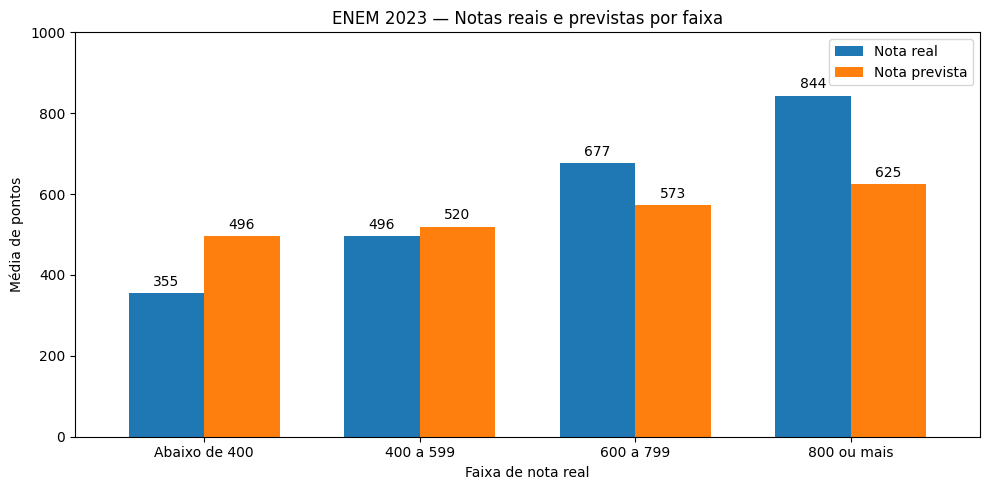

In [23]:
# ETAPA 23 - Comparação entre notas reais e previstas

df_comparacao = (
    df_erros.groupBy("faixa_nota")
    .agg(
        F.avg("label").alias("Nota real"),
        F.avg("prediction").alias("Nota prevista")
    )
    .toPandas()
)

ordem = [
    "Abaixo de 400",
    "400 a 599",
    "600 a 799",
    "800 ou mais"
]

df_comparacao["faixa_nota"] = pd.Categorical(
    df_comparacao["faixa_nota"],
    categories=ordem,
    ordered=True
)

df_comparacao = df_comparacao.sort_values("faixa_nota")

ax = df_comparacao.plot(
    x="faixa_nota",
    y=["Nota real", "Nota prevista"],
    kind="bar",
    figsize=(10, 5),
    rot=0,
    width=0.7
)

ax.set_title("ENEM 2023 — Notas reais e previstas por faixa")
ax.set_xlabel("Faixa de nota real")
ax.set_ylabel("Média de pontos")
ax.set_ylim(0, 1000)
ax.legend(title="")

for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

### Comparação entre notas reais e previstas

O gráfico compara as médias das notas reais e previstas pelo modelo de regressão, considerando quatro faixas de desempenho em Matemática.

Observa-se que as previsões apresentam maior proximidade com as médias reais na faixa de 400 a 599 pontos.

Para participantes com notas inferiores a 400 pontos, o modelo apresenta tendência de superestimação. Já nas faixas superiores a 600 pontos, ocorre subestimação, especialmente entre os participantes com notas iguais ou superiores a 800 pontos.

Esses resultados indicam que o modelo tende a concentrar suas previsões em valores intermediários, apresentando maior dificuldade para estimar desempenhos extremos.

A visualização considera os 538.428 registros do conjunto de teste e complementa as métricas RMSE, MAE e R² utilizadas na avaliação do modelo.

## Conclusão

Este trabalho investigou a relação entre as características socioeconômicas dos participantes e o desempenho em Matemática no ENEM 2023, utilizando Apache Spark e técnicas de Machine Learning.

A base original continha 3.933.955 registros. Após a seleção dos participantes presentes na prova de Matemática e com notas válidas, foram utilizados 2.692.427 registros, atendendo ao requisito de processamento de dados massivos proposto na disciplina.

A análise exploratória identificou diferenças expressivas entre os grupos socioeconômicos. Na variável renda familiar, a média de Matemática passou de 454,69 pontos entre participantes sem renda familiar declarada para 685,82 pontos entre aqueles com renda superior a R$ 26.400 mensais, uma diferença de 231,13 pontos.

Também foram observadas diferenças nas notas relacionadas à escolaridade dos responsáveis, ao acesso à internet e ao tipo de escola informado.

Para investigar a capacidade preditiva dessas características, foi desenvolvido um modelo de regressão linear com regularização Ridge, utilizando o Spark ML. Após o ajuste dos hiperparâmetros, o modelo definitivo apresentou RMSE de 114,32 pontos, MAE de 89,93 pontos e R² de 0,2462.

Em comparação com o modelo de referência, que utiliza a média das notas de treinamento, a regressão apresentou menor erro de previsão.

O R² indica que as características socioeconômicas selecionadas explicam aproximadamente 24,62% da variação das notas de Matemática no conjunto de teste.

Entretanto, a análise dos erros demonstrou que o modelo apresenta maior dificuldade para prever desempenhos muito baixos ou elevados, concentrando suas estimativas em valores intermediários.

Os resultados indicam que as condições socioeconômicas possuem associação relevante com o desempenho educacional, mas não determinam individualmente as notas dos participantes. Além disso, as relações identificadas são estatísticas e não permitem estabelecer causalidade.

Como limitações do estudo, destacam-se a utilização de apenas cinco características socioeconômicas para a previsão das notas, a presença de categorias que representam informações não declaradas ou desconhecidas e a maior dificuldade do modelo para estimar desempenhos extremos. Além disso, os resultados demonstram associações estatísticas, não permitindo estabelecer relações de causa e efeito.

Como possibilidades de melhoria, recomenda-se investigar outras características educacionais, avaliar diferentes modelos de regressão e utilizar um conjunto de teste independente em estudos futuros.

Conclui-se que o Apache Spark permitiu organizar e processar milhões de registros do ENEM, demonstrando sua aplicação em análises de grande volume de dados e contribuindo para a investigação das desigualdades educacionais no Brasil.